# Stacking Ensemble: Training & Evaluation (Train/Val/Test Split)


### 1. Stratified Shuffled Split (70% Train, 15% Val, 15% Test)


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve,
    roc_auc_score, precision_recall_fscore_support
)

# load engineered dataset
data_path = os.path.join('..', 'data', 'processed', 'flood_data_featured.csv')
df = pd.read_csv(data_path)

# separate features and target
ignore_cols = ['Station_Names', 'Year', 'Month', 'Period', 'Flood?']
feature_cols = [c for c in df.columns if c not in ignore_cols]

X = df[feature_cols]
y = df['Flood?']

# 3-way stratified shuffled split: 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Dataset Split (Stratified & Shuffled):")
print(f"  - Train Set:      {X_train.shape[0]:,} samples (70%) | Floods: {int(y_train.sum()):,}")
print(f"  - Validation Set: {X_val.shape[0]:,} samples (15%) | Floods: {int(y_val.sum()):,}")
print(f"  - Test Set:       {X_test.shape[0]:,} samples (15%) | Floods: {int(y_test.sum()):,}")
print(f"Total Features:     {len(feature_cols)}")


Dataset Split (Stratified & Shuffled):
  - Train Set:      14,380 samples (70%) | Floods: 2,892
  - Validation Set: 3,082 samples (15%) | Floods: 620
  - Test Set:       3,082 samples (15%) | Floods: 620
Total Features:     59



### 2. Train Stacking Ensemble, Threshold Tuning on Validation, and Test Evaluation


In [2]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb

# base estimators
base_estimators = [
    ('xgb', xgb.XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.08, scale_pos_weight=3.97, random_state=42, eval_metric='logloss')),
    ('rf', RandomForestClassifier(n_estimators=150, max_depth=None, class_weight='balanced', random_state=42, n_jobs=-1)),
    ('hgb', HistGradientBoostingClassifier(max_iter=150, max_depth=7, learning_rate=0.08, class_weight='balanced', random_state=42))
]

# Stacking Ensemble with Logistic Regression meta-learner
model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(class_weight='balanced', max_iter=1000),
    cv=3,
    n_jobs=1
)

# fit model on training split
model.fit(X_train, y_train)

# validation threshold tuning (0.10 to 0.90)
val_probs = model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.05)
thresh_results = []

for t in thresholds:
    p = (val_probs >= t).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y_val, p, average='binary', zero_division=0)
    thresh_results.append([round(t, 2), prec, rec, f1])

results_df = pd.DataFrame(thresh_results, columns=['Threshold', 'Precision', 'Recall', 'F1-score'])
print("Validation Threshold Tuning Results:")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# evaluate on unseen test set using default threshold (0.50)
test_probs = model.predict_proba(X_test)[:, 1]
test_preds = model.predict(X_test)
roc_auc = roc_auc_score(y_test, test_probs)

print("\nClassification Report (Test Set - Threshold 0.50):")
print(classification_report(y_test, test_preds, digits=4))
print(f"ROC-AUC Score: {roc_auc:.4f}")

# save trained model artifact
joblib.dump(model, os.path.join('..', 'models', 'stacking_ensemble_model.pkl'))
print(f"Model saved to models/stacking_ensemble_model.pkl")


Validation Threshold Tuning Results:
 Threshold  Precision  Recall  F1-score
    0.1000     0.8497  0.9758    0.9084
    0.1500     0.8703  0.9742    0.9193
    0.2000     0.8824  0.9677    0.9231
    0.2500     0.8927  0.9661    0.9280
    0.3000     0.8952  0.9645    0.9286
    0.3500     0.8991  0.9629    0.9299
    0.4000     0.9081  0.9565    0.9317
    0.4500     0.9122  0.9548    0.9330
    0.5000     0.9149  0.9532    0.9336
    0.5500     0.9158  0.9468    0.9310
    0.6000     0.9185  0.9452    0.9316
    0.6500     0.9214  0.9452    0.9331
    0.7000     0.9255  0.9419    0.9337
    0.7500     0.9314  0.9419    0.9366
    0.8000     0.9358  0.9403    0.9381
    0.8500     0.9397  0.9306    0.9352

Classification Report (Test Set - Threshold 0.50):
              precision    recall  f1-score   support

         0.0     0.9946    0.9716    0.9829      2462
         1.0     0.8966    0.9790    0.9360       620

    accuracy                         0.9731      3082
   macro avg 

### 3. Graph 1: Confusion Matrix Heatmap


<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



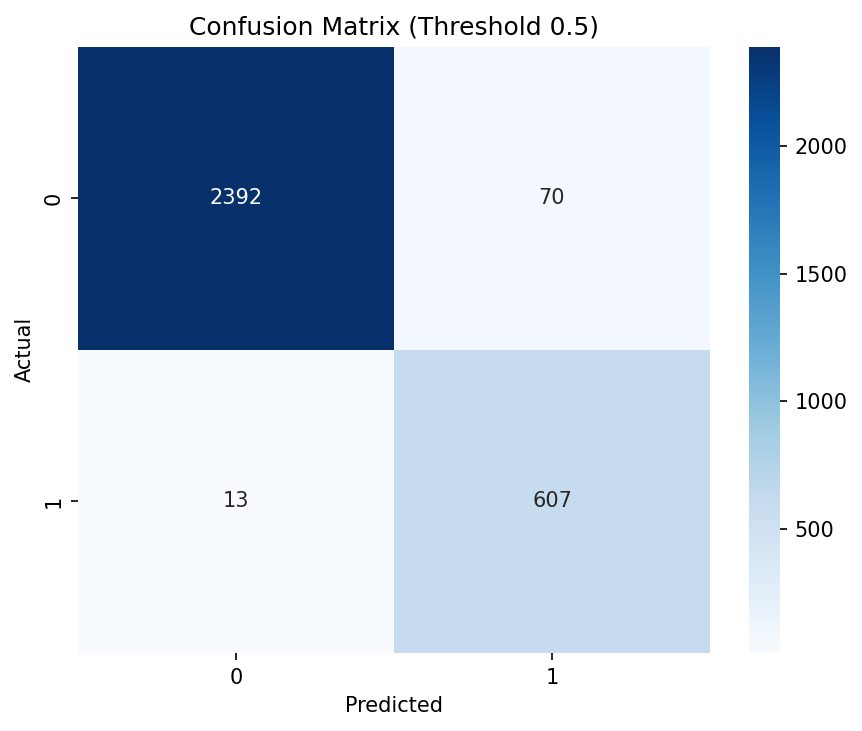

In [3]:
# Plot 1: Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Threshold 0.5)')
plt.tight_layout()
plt.savefig(os.path.join('..', 'reports', 'stacking_ensemble_model_confusion_matrix.png'), dpi=150)
plt.show()


### 4. Graph 2: Receiver Operating Characteristic (ROC) Curve


<string>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



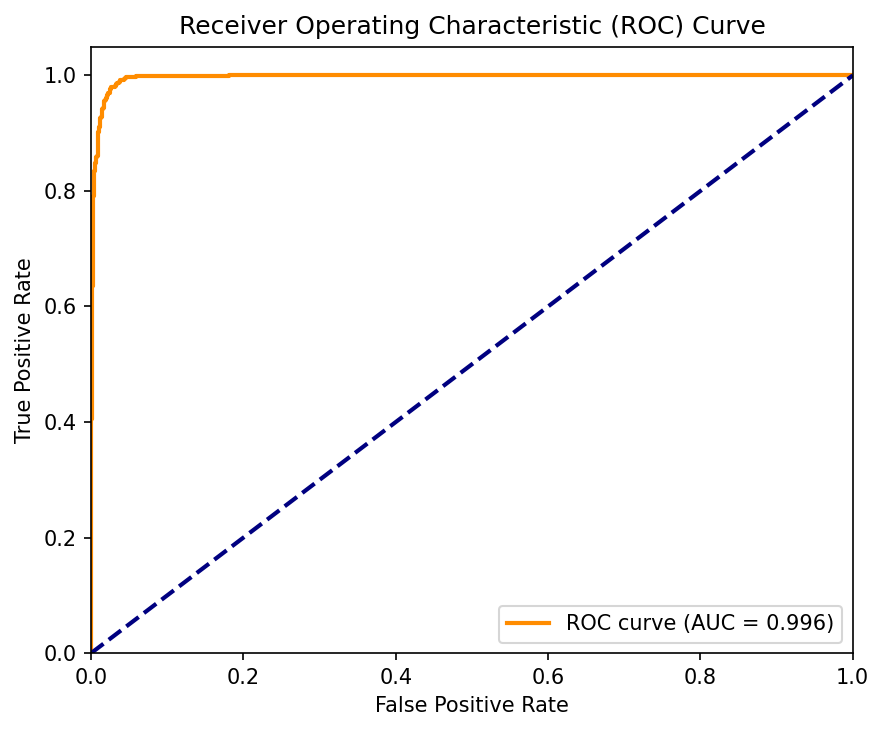

In [4]:
# Plot 2: Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join('..', 'reports', 'stacking_ensemble_model_roc_curve.png'), dpi=150)
plt.show()


### 5. Graph 3: Predicted Probability Distribution


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



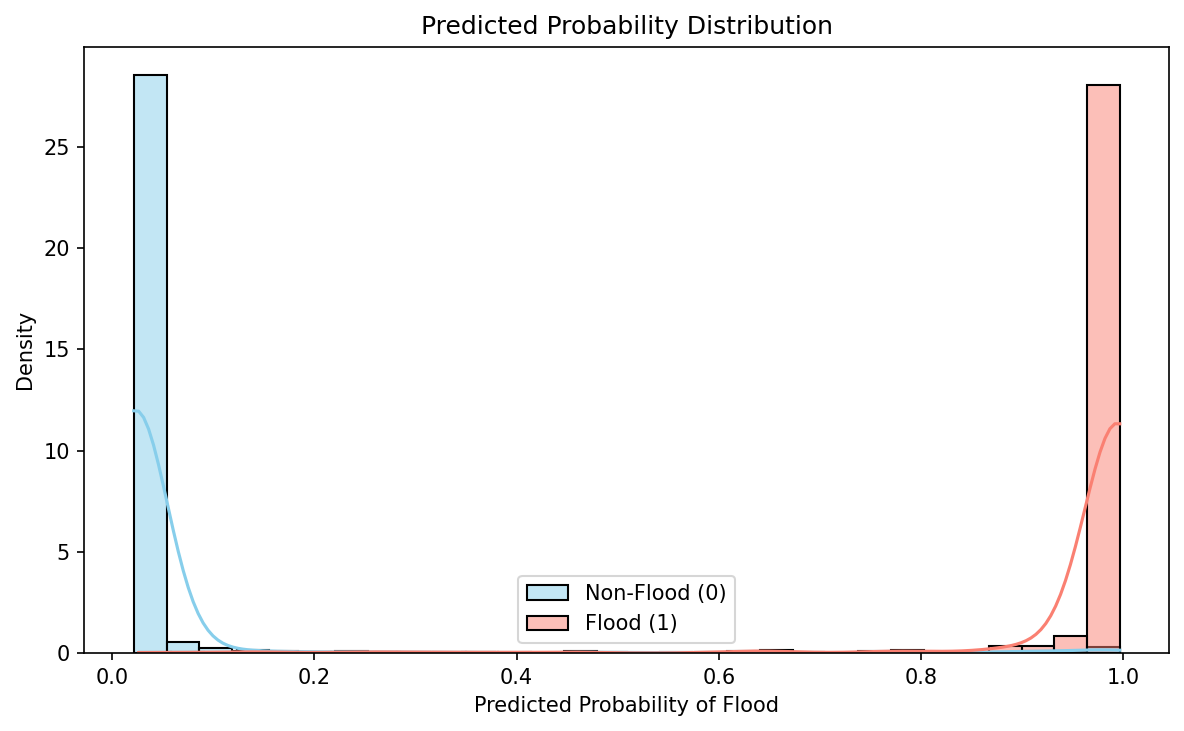

In [5]:
# Plot 3: Predicted Probability Distribution
plt.figure(figsize=(8, 5))
sns.histplot(test_probs[y_test == 0], color='skyblue', label='Non-Flood (0)', bins=30, stat='density', kde=True)
sns.histplot(test_probs[y_test == 1], color='salmon', label='Flood (1)', bins=30, stat='density', kde=True)
plt.xlabel('Predicted Probability of Flood')
plt.ylabel('Density')
plt.title('Predicted Probability Distribution')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join('..', 'reports', 'stacking_ensemble_model_probability_distribution.png'), dpi=150)
plt.show()


### 6. Graph 4: Top 15 Feature Importances


<string>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



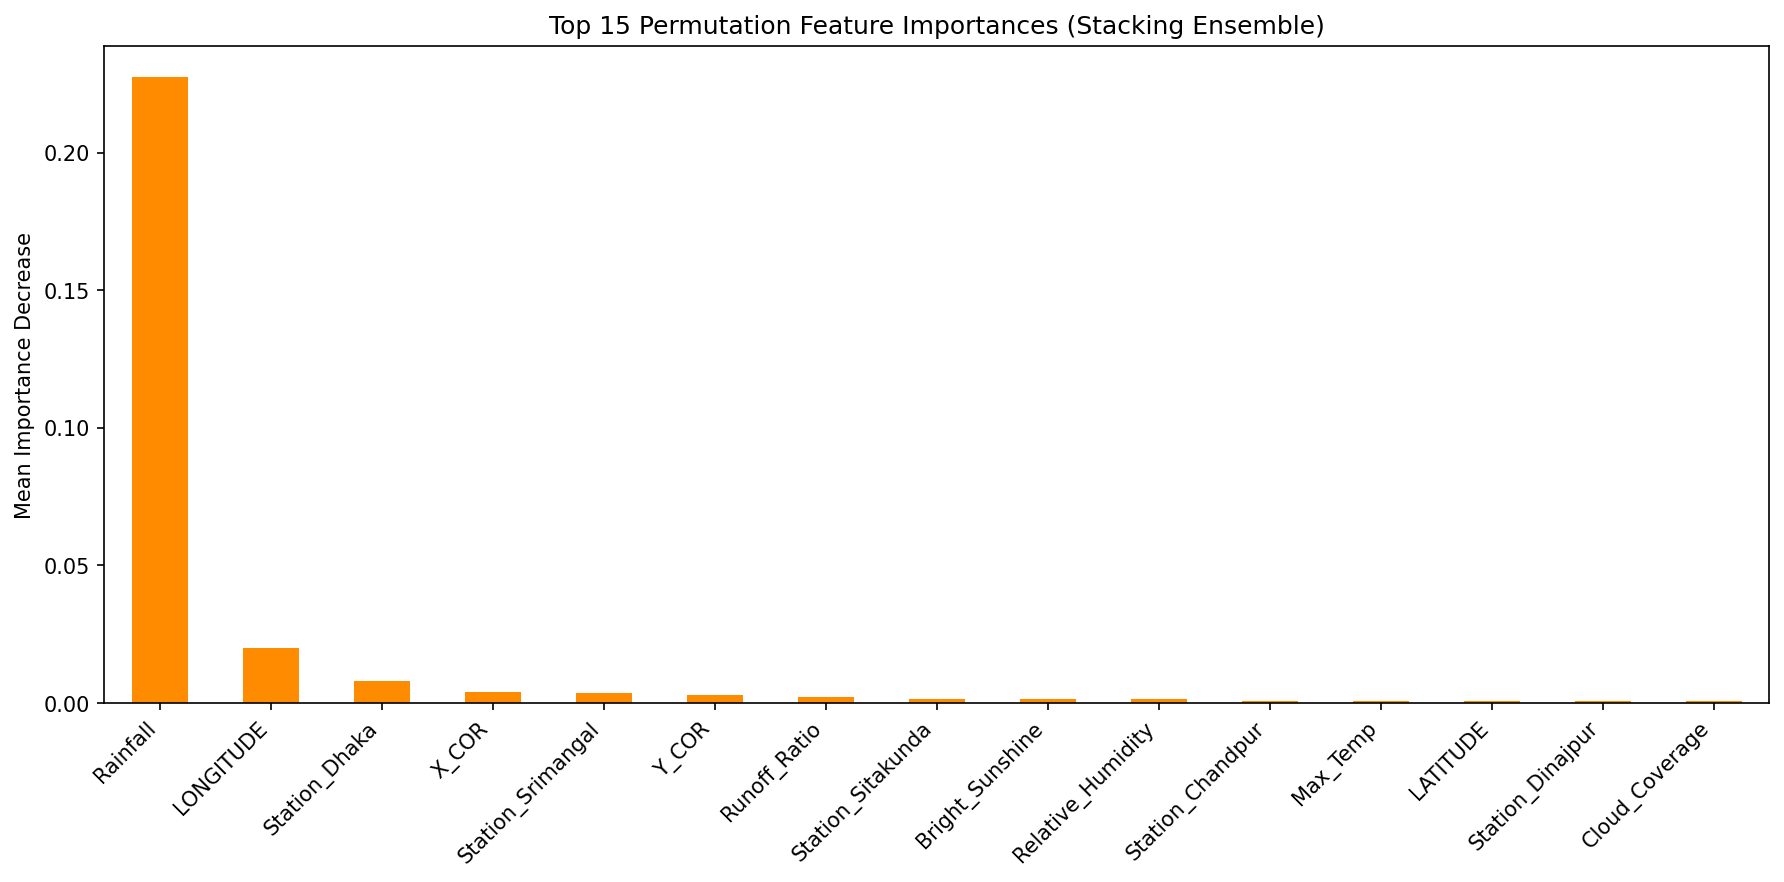

In [6]:
# Plot 4: Component Base Estimator Weights & Correlations
from sklearn.inspection import permutation_importance
result = permutation_importance(model, X_val, y_val, n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = pd.Series(result.importances_mean, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
perm_imp[:15].plot(kind='bar', color='darkorange')
plt.title('Top 15 Permutation Feature Importances (Stacking Ensemble)')
plt.ylabel('Mean Importance Decrease')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join('..', 'reports', 'stacking_ensemble_model_feature_importance.png'), dpi=150)
plt.show()
